# Read PK curves and score HTPK predictions against them

This notebook reads the machine-readable concentration–time dataset, plots a representative set of
10 cases, and computes the metrics used to compare predicted with measured profiles. It covers single
curves with and without bounds, the multi-replicate case, and all species and routes.

**Files**

| File | Content |
|---|---|
| `data/Cptimecurves_machine_readable.csv` | measured profiles (the dataset) |
| `notebook/htpk_predictions.csv` | predicted Cp–time curves for the 10 cases |
| `notebook/htpk_metrics.py` | metric implementation (numpy/pandas/matplotlib only) |

**Predictions.** The curves were computed with the high-throughput PK (HTPK) module of ADMET Predictor 14.0
(`SIMFaFb`, stock species-specific settings, dose and dosage form of each case). ADMET Predictor is commercial,
so the curves are provided pre-computed. The keys `Compound`, `Smiles`, `Dose (mg)`, `Route`, `Species` match
the dataset.

**Metrics.** These follow the original benchmark analysis; the full description is in the docstring of `htpk_metrics.py`.

1. Replicates are interpolated onto a common time grid (the window covered by all replicates) and averaged.
2. The predicted curve is averaged in 1-minute bins and interpolated onto the measured time points.
3. If a case has complete bounds, a prediction outside `[lower, upper]` is scored against the violated bound,
   and a prediction inside the bounds counts as exact.
4. Points at ~0 concentration (typically t = 0) are excluded.

The main metric is the **mean absolute log2 error (MAL2E)**: 1 means a two-fold error on average.

## 1. Install required packages

Run once in the notebook's Python environment.

In [1]:
%pip install pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import importlib.metadata as metadata

for package in ("pandas", "numpy", "matplotlib"):
    print(f"{package}: {metadata.version(package)}")

pandas: 3.1.1
numpy: 2.5.4
matplotlib: 3.11.2


## 2. Imports and configuration

The path checks let the notebook run with either the repository root or `notebook/` as the working directory.

In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

NOTEBOOK_DIR = next(p for p in (Path.cwd(), Path.cwd() / "notebook") if (p / "htpk_metrics.py").is_file())
sys.path.insert(0, str(NOTEBOOK_DIR))
import htpk_metrics as hm

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 3. Load the dataset and the predictions

The required headers are validated before any curve is selected.

In [4]:
DATA_PATH = (NOTEBOOK_DIR.parent / "data" / "Cptimecurves_machine_readable.csv").resolve()
PREDICTIONS_PATH = (NOTEBOOK_DIR / "htpk_predictions.csv").resolve()

df = pd.read_csv(DATA_PATH, dtype={"Compound": str})
predictions = pd.read_csv(PREDICTIONS_PATH, dtype={"Compound": str})
print(f"Loaded {len(df):,} observations from {DATA_PATH}")
print(f"Loaded {len(predictions):,} predicted points from {PREDICTIONS_PATH}")

REQUIRED_COLUMNS = [*hm.CASE_COLUMNS, hm.TIME, hm.CONC, hm.REPLICATE, hm.LOWER, hm.UPPER]
missing_columns = sorted(set(REQUIRED_COLUMNS) - set(df.columns))
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")
display(df.head())

Loaded 2,117 observations from C:\Users\rbachorz\Projects\httk\HTPK_workflow\httk\new_PKDB\pk-datasets\data\Cptimecurves_machine_readable.csv
Loaded 13,867 predicted points from C:\Users\rbachorz\Projects\httk\HTPK_workflow\httk\new_PKDB\pk-datasets\notebook\htpk_predictions.csv


,Compound,Smiles,Dose (mg),Dose (mg/kg),Route,Species,Source,Time (h),Concentration (ng/mL),Replicate,Lower bound,Upper bound,ADMET_Risk,ECCS_Class,RuleOf5,CyclPept_filter,Macrocycle,PROTAC_filter
0,32,C(O)(Cn1c2c(c(-c3cc4c(cc(OC5CC5)cc4)cc3)n1)c(n...,10.0,1.0,IRS,dog,Vidadala_2016,0.00,0.000,1,0.000,0.000,4.220607,Class_2,0,0,0,0
1,32,C(O)(Cn1c2c(c(-c3cc4c(cc(OC5CC5)cc4)cc3)n1)c(n...,10.0,1.0,IRS,dog,Vidadala_2016,0.25,194.730,1,116.838,311.568,4.220607,Class_2,0,0,0,0
2,32,C(O)(Cn1c2c(c(-c3cc4c(cc(OC5CC5)cc4)cc3)n1)c(n...,10.0,1.0,IRS,dog,Vidadala_2016,0.50,623.136,1,506.298,739.974,4.220607,Class_2,0,0,0,0
3,32,C(O)(Cn1c2c(c(-c3cc4c(cc(OC5CC5)cc4)cc3)n1)c(n...,10.0,1.0,IRS,dog,Vidadala_2016,1.00,506.298,1,389.460,623.136,4.220607,Class_2,0,0,0,0
4,32,C(O)(Cn1c2c(c(-c3cc4c(cc(OC5CC5)cc4)cc3)n1)c(n...,10.0,1.0,IRS,dog,Vidadala_2016,1.50,467.352,1,389.460,545.244,4.220607,Class_2,0,0,0,0


## 4. The 10 cases

A case is one compound × dose × route × species. The cases are the ones that have predictions. They were
chosen to cover every kind of measured data: single curves without bounds, with full bounds and with partial
bounds, and cases with several replicates. Together they span all species and routes. The category below
describes the data in this file.

In [5]:
case_keys = predictions[hm.CASE_COLUMNS].drop_duplicates().reset_index(drop=True)
measured = df.merge(case_keys, on=hm.CASE_COLUMNS, how="inner")
missing_cases = len(case_keys) - len(measured[hm.CASE_COLUMNS].drop_duplicates())
if missing_cases:
    raise ValueError(f"{missing_cases} predicted case(s) not found in the dataset")

measured_by_case = {k: g for k, g in measured.groupby(hm.CASE_COLUMNS, sort=False)}
predicted_by_case = {k: g.sort_values(hm.TIME) for k, g in predictions.groupby(hm.CASE_COLUMNS, sort=False)}

cases = pd.DataFrame([
    {
        **dict(zip(hm.CASE_COLUMNS, key)),
        "case": hm.case_label(dict(zip(hm.CASE_COLUMNS, key))),
        "category": hm.case_category(data),
        "replicates": data[hm.REPLICATE].nunique(),
        "samples": len(data),
        "last time (h)": data[hm.TIME].max(),
        "bounds fraction": round(data[hm.LOWER].notna().mean(), 2),
        "_key": key,
    }
    for key, data in measured_by_case.items()
]).sort_values(["category", "Species"]).reset_index(drop=True)
display(cases.drop(columns=["Smiles", "_key"]))
print("species:", sorted(cases["Species"].unique()), "| routes:", sorted(cases["Route"].unique()))

,Compound,Dose (mg),Route,Species,case,category,replicates,samples,last time (h),bounds fraction
0,fexofenadine,80.000,IRS,human,fexofenadine | human | IRS | 80 mg,"multiple curves, full bounds",2,29,48.0,1.0
1,edoxaban,60.000,IRT,human,edoxaban | human | IRT | 60 mg,"multiple curves, full bounds",4,62,72.0,1.0
2,Sildenafil,50.000,IRT,human,Sildenafil | human | IRT | 50 mg,"multiple curves, full bounds",3,45,18.0,1.0
3,Benzatropine,264.375,IRS,dog,Benzatropine | dog | IRS | 264.375 mg,"single curve, full bounds",1,14,24.0,1.0
4,ledipasvir,60.000,IRT,human,ledipasvir | human | IRT | 60 mg,"single curve, full bounds",1,17,96.0,1.0
5,32,4.000,IRS,monkey,32 | monkey | IRS | 4 mg,"single curve, full bounds",1,11,24.0,1.0
6,A5,2.500,IRS,rat,A5 | rat | IRS | 2.5 mg,"single curve, full bounds",1,9,24.0,1.0
7,Rifabutin,150.000,IRS,human,Rifabutin | human | IRS | 150 mg,"single curve, no bounds",1,19,168.0,0.0
8,8,0.250,IRS,mouse,8 | mouse | IRS | 0.25 mg,"single curve, no bounds",1,10,24.0,0.0
9,32,1.250,IV,rat,32 | rat | IV | 1.25 mg,"single curve, no bounds",1,11,24.0,0.0


species: ['dog', 'human', 'monkey', 'mouse', 'rat'] | routes: ['IRS', 'IRT', 'IV']


## 5. Metric settings

`MetricSettings()` reproduces the original analysis: error bounds used, in-bound predictions counted as exact,
and 1-minute resampling of the predicted curve. Each case is also scored without bounds for comparison.
`resample_minutes=None` switches to exact interpolation of the predicted curve.

In [6]:
SETTINGS = {
    "with bounds": hm.MetricSettings(),
    "no bounds": hm.MetricSettings(use_error_bounds=False),
}
LOG_Y = False  # log concentration axis in the figures
SETTINGS

{'with bounds': MetricSettings(use_error_bounds=True, zero_error_within_bounds=True, min_threshold=1e-10, resample_minutes=1.0),
 'no bounds': MetricSettings(use_error_bounds=False, zero_error_within_bounds=True, min_threshold=1e-10, resample_minutes=1.0)}

## 6. Metrics per case

`bounds_used` shows whether bounds were applied. They are used only when they are complete for every point
of the case. `n_points − n_valid_points` points were excluded as ~0.

In [7]:
rows = []
for _, case in cases.iterrows():
    replicates = hm.replicate_frames(measured_by_case[case["_key"]])
    prediction = predicted_by_case[case["_key"]]
    for name, settings in SETTINGS.items():
        rows.append({"case": case["case"], "settings": name, **hm.case_metrics(replicates, prediction, settings)})
metrics_long = pd.DataFrame(rows)

primary = metrics_long[metrics_long["settings"] == "with bounds"].set_index("case")
plain = metrics_long[metrics_long["settings"] == "no bounds"].set_index("case")
metrics = cases.set_index("case")[["category", "replicates"]].join(
    primary[["bounds_used", "n_points", "n_valid_points", "Mean_Absolute_Log2_Error", "Mean_Log2_Error", "RMSE_Log2", "R_squared"]]
)
metrics.insert(metrics.columns.get_loc("Mean_Absolute_Log2_Error") + 1, "MAL2E no bounds", plain["Mean_Absolute_Log2_Error"])
metrics = metrics.rename(columns={"Mean_Absolute_Log2_Error": "MAL2E"})
display(metrics.round(3))

,category,replicates,bounds_used,n_points,n_valid_points,MAL2E,MAL2E no bounds,Mean_Log2_Error,RMSE_Log2,R_squared
case,,,,,,,,,,
fexofenadine | human | IRS | 80 mg,"multiple curves, full bounds",2,True,15,14,2.049,2.508,0.814,2.459,0.008
edoxaban | human | IRT | 60 mg,"multiple curves, full bounds",4,True,23,22,0.536,1.063,-0.262,0.981,0.938
Sildenafil | human | IRT | 50 mg,"multiple curves, full bounds",3,True,19,18,0.012,0.700,0.012,0.023,0.999
Benzatropine | dog | IRS | 264.375 mg,"single curve, full bounds",1,True,14,13,0.729,1.088,0.729,1.173,0.963
ledipasvir | human | IRT | 60 mg,"single curve, full bounds",1,True,17,16,2.732,2.884,-2.732,2.873,0.291
32 | monkey | IRS | 4 mg,"single curve, full bounds",1,True,11,10,0.550,0.994,0.550,0.871,0.698
A5 | rat | IRS | 2.5 mg,"single curve, full bounds",1,True,9,8,1.012,1.459,-0.015,1.297,0.244
Rifabutin | human | IRS | 150 mg,"single curve, no bounds",1,False,19,18,1.824,1.824,-1.586,3.078,0.863
8 | mouse | IRS | 0.25 mg,"single curve, no bounds",1,False,10,9,1.489,1.489,-1.489,1.921,0.592


`Mean_Log2_Error` > 0 means over-prediction on average (1 = two-fold), < 0 means under-prediction.

## 7. Predicted vs measured curves

Measured replicates are shown in orange, with the bounds as a shaded band where the dataset reports them.
The prediction is shown in blue up to the last measured time.

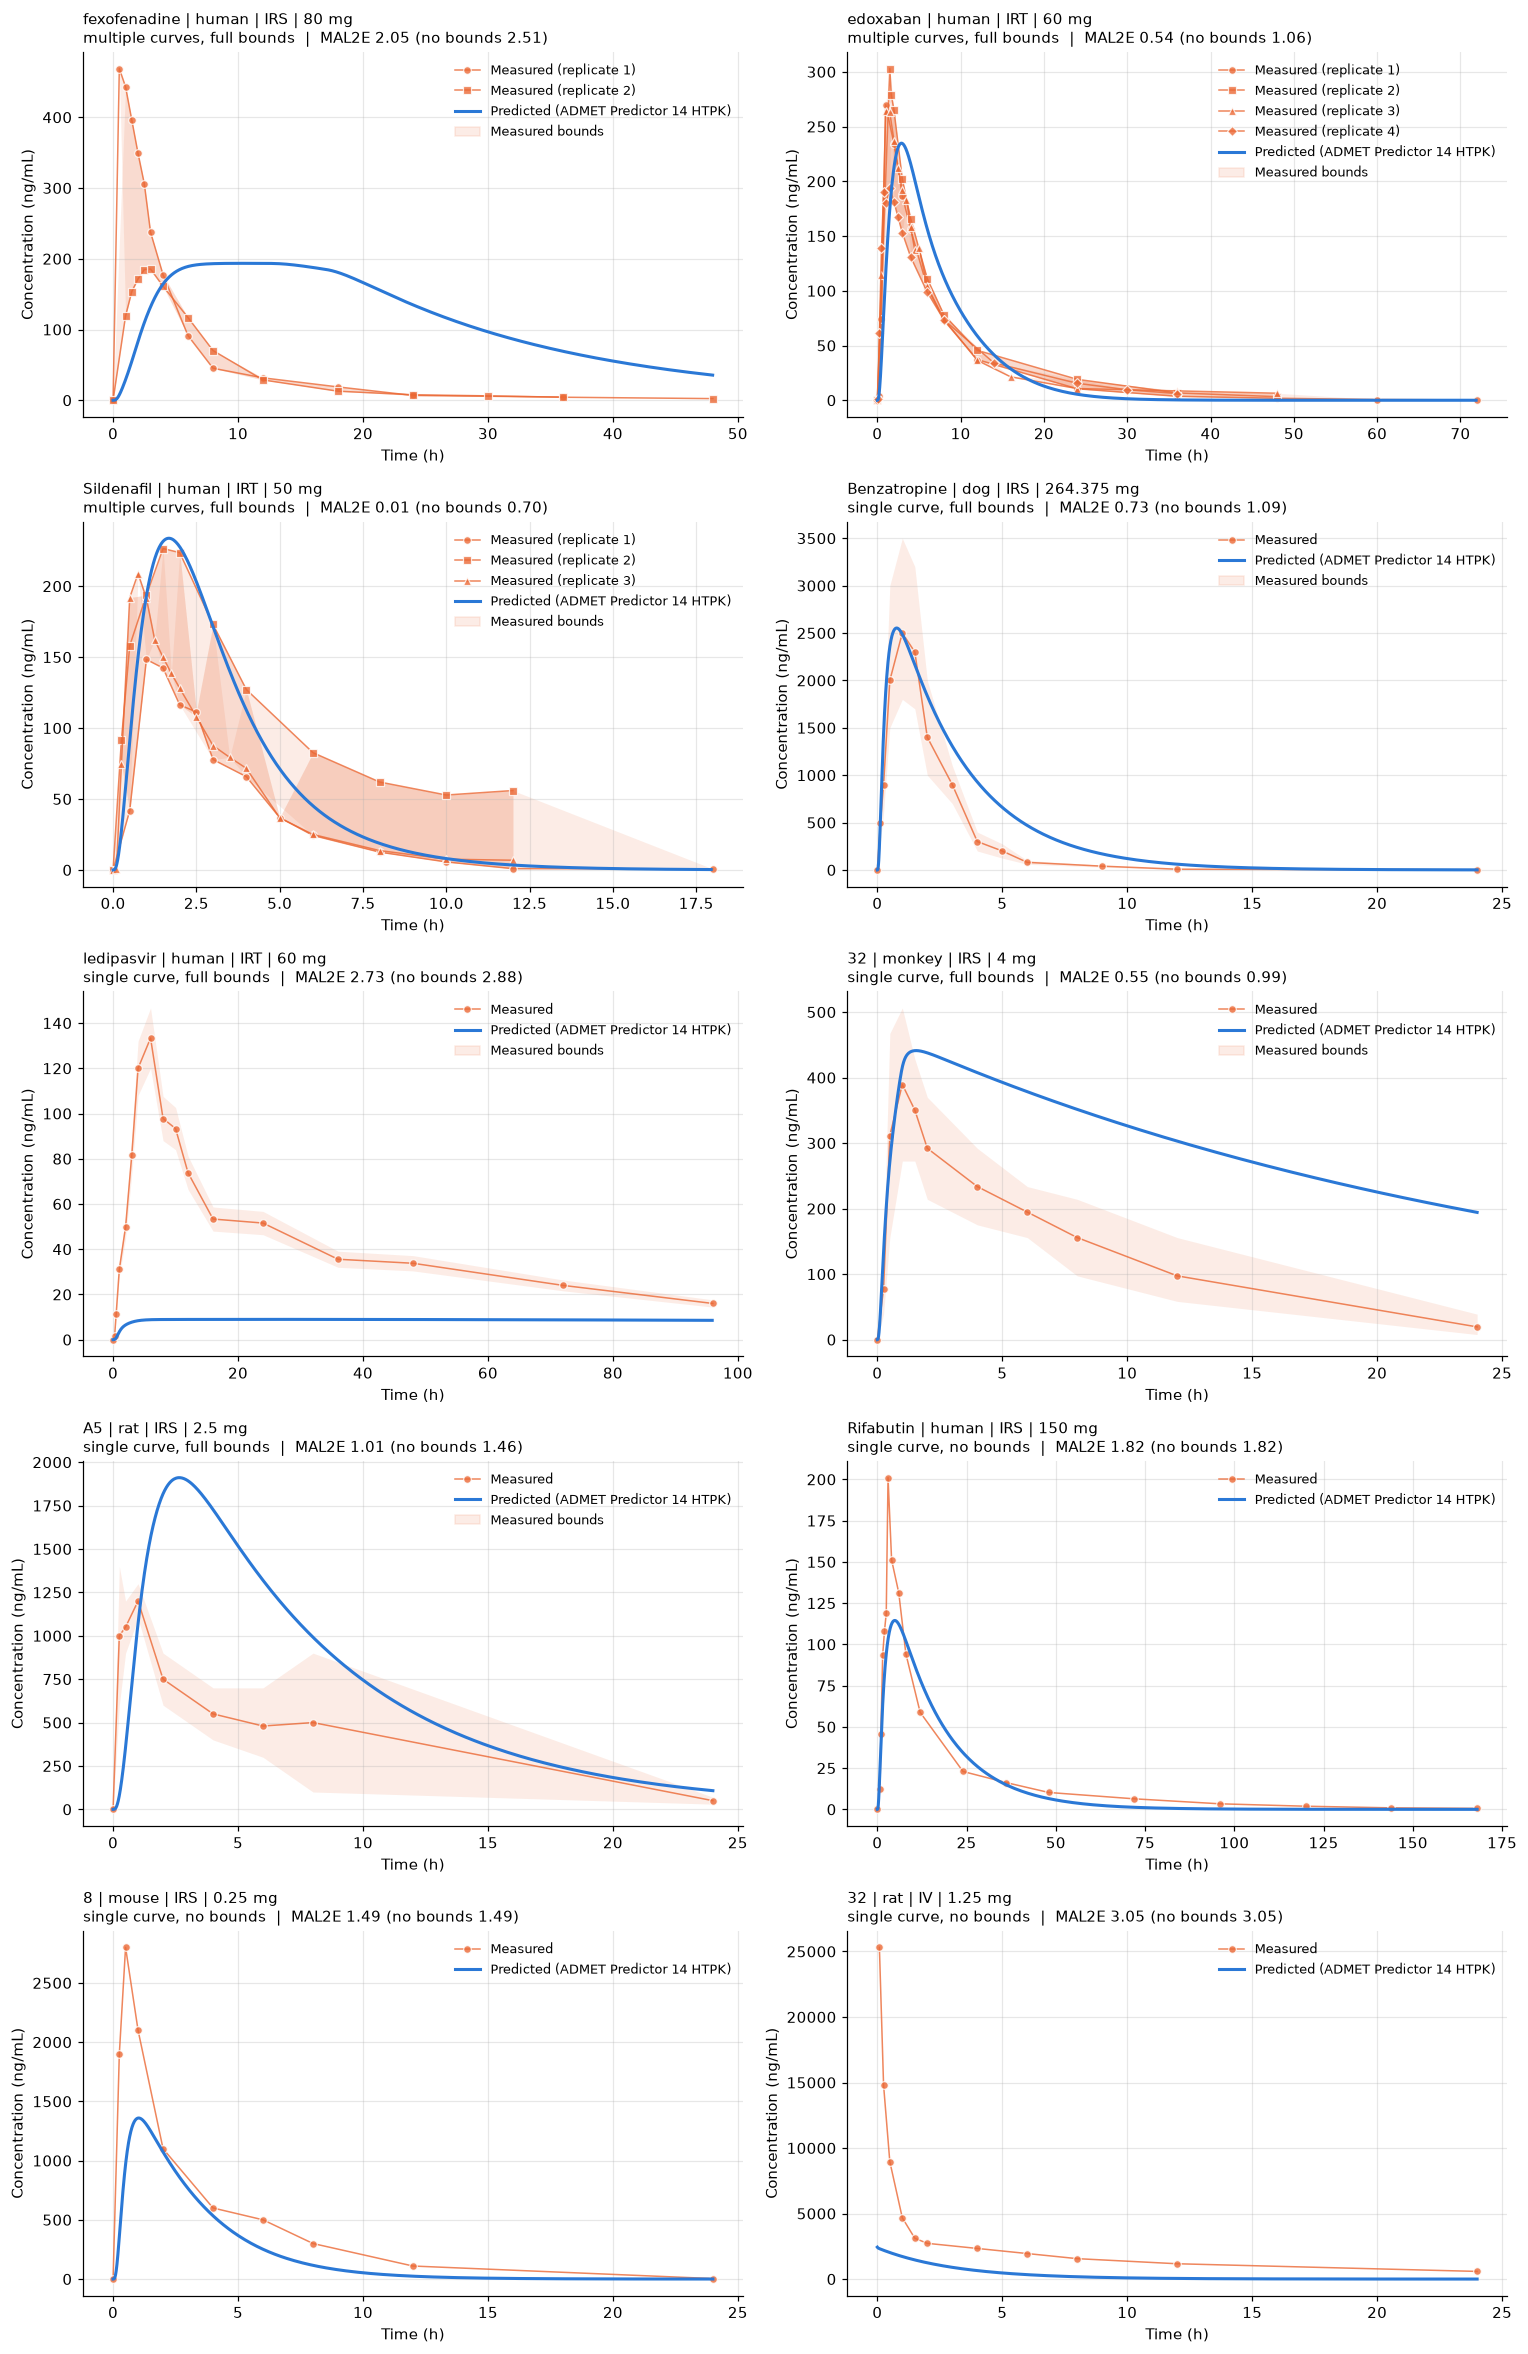

In [8]:
ncols = 2
nrows = int(np.ceil(len(cases) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.3 * nrows), squeeze=False)
for ax, (_, case) in zip(axes.flat, cases.iterrows()):
    row = metrics.loc[case["case"]]
    hm.plot_case(
        ax,
        hm.replicate_frames(measured_by_case[case["_key"]]),
        predicted_by_case[case["_key"]],
        title=f"{case['case']}\n{case['category']}  |  MAL2E {row['MAL2E']:.2f} (no bounds {row['MAL2E no bounds']:.2f})",
        log_y=LOG_Y,
        predicted_label="Predicted (ADMET Predictor 14 HTPK)",
    )
for ax in axes.flat[len(cases):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

## 8. Summary by category

In [9]:
summary = metrics.groupby("category").agg(
    cases=("replicates", "size"),
    bounds_used=("bounds_used", "sum"),
    MAL2E=("MAL2E", "mean"),
    MAL2E_no_bounds=("MAL2E no bounds", "mean"),
    mean_log2_error=("Mean_Log2_Error", "mean"),
)
display(summary.round(3))
print(f"Mean MAL2E over the {len(metrics)} cases: {metrics['MAL2E'].mean():.3f} "
      f"(no bounds: {metrics['MAL2E no bounds'].mean():.3f})")

,cases,bounds_used,MAL2E,MAL2E_no_bounds,mean_log2_error
category,,,,,
"multiple curves, full bounds",3,3,0.865,1.424,0.188
"single curve, full bounds",4,4,1.256,1.606,-0.367
"single curve, no bounds",3,0,2.120,2.120,-2.040


Mean MAL2E over the 10 cases: 1.398 (no bounds: 1.706)


## 9. Optional: save the figure and the metrics

Set the flags to `True` to write files under `notebook/outputs/`.

In [10]:
SAVE_FIGURE = False
EXPORT_METRICS = False
OUTPUT_DIR = NOTEBOOK_DIR / "outputs"

if SAVE_FIGURE or EXPORT_METRICS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if SAVE_FIGURE:
    fig.savefig(OUTPUT_DIR / "htpk_vs_measured.png", dpi=150, bbox_inches="tight")
    print(f"Figure saved in {OUTPUT_DIR}")
if EXPORT_METRICS:
    metrics_long.to_csv(OUTPUT_DIR / "htpk_metrics.csv", index=False)
    print(f"Metrics saved in {OUTPUT_DIR}")